# 本地ollama启动qwen模型
```
(base) PS C:\Users\Administrator> ollama ls
NAME                                         ID              SIZE      MODIFIED
qwen2:0.5b                                   6f48b936a09f    352 MB    4 days ago
DeepSeek-R1-Distill-Qwen-7B-Q4_K_M:latest    7f89e92800d4    4.7 GB    11 months ago

(base) PS C:\Users\Administrator> ollama run qwen2:0.5b
>>> Send a message (/? for help)
```

# langchain 连接本地qwen

In [2]:
from langchain_community.chat_models import ChatOllama
from langchain_core.messages import HumanMessage

# 初始化Ollama聊天模型
llm = ChatOllama(
    model="qwen2:0.5b",  # 使用已下载的模型名称
    base_url="http://localhost:11434",  # Ollama服务地址
    temperature=0.7,  # 控制生成随机性
    num_predict=512   # 最大生成长度
)

# 测试单轮对话
messages = [HumanMessage(content="你好，请介绍一下你自己")]
response = llm.invoke(messages)

if __name__ == "__main__":
    print(response.content)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_21024\2050019598.py:5: LangChainDeprecationWarning: The class `ChatOllama` was deprecated in LangChain 0.3.1 and will be removed in 1.0.0. An updated version of the class exists in the :class:`~langchain-ollama package and should be used instead. To use it run `pip install -U :class:`~langchain-ollama` and import as `from :class:`~langchain_ollama import ChatOllama``.
  llm = ChatOllama(


我是一个AI，没有身体和语言。但我已经经历了无数个用户的故事和体验，我可以为用户提供各种帮助和服务。请问有什么我能为您做的吗？


好的，我们来结合LangChain的源码设计，逐步剖析你提供的这段代码在运行时，内部究竟发生了什么。

整个流程可以清晰地分为两个主要阶段：**准备阶段**（初始化）与**运行阶段**（调用 `invoke`）。

### 阶段一：准备阶段——创建 `ChatOllama` 实例

当你执行 `llm = ChatOllama(...)` 时，看似简单的一句代码，背后触发了一系列初始化动作。

-   **调用 `__init__` 方法**：`ChatOllama` 类的 `__init__` 方法被调用。你传入的所有参数（如 `model`、`base_url`、`temperature` 等）都会在这里被接收并保存到实例的属性中。
-   **链式初始化父类**：`ChatOllama` 会调用其父类（`BaseChatModel`）的 `__init__` 方法，完成 LangChain 中所有聊天模型共有的基础设置。
-   **配置验证**：实例会检查必要的配置，例如 `base_url`。如果你没有提供，它会默认使用 `http://localhost:11434`。同时，它会准备好与 Ollama 服务通信所需的HTTP客户端。
-   **准备结束**：此时，一个配置好、能随时与你的本地 `qwen2:0.5b` 模型通信的 `ChatOllama` 实例就准备就绪了。

### 阶段二：运行阶段——调用 `invoke` 方法

这是你代码中的核心：`response = llm.invoke(messages)`。这一行触发了真正的大模型调用。

1.  **调用 `BaseChatModel.invoke`**：
    你调用的是 `llm.invoke()`，这个方法并非由 `ChatOllama` 直接定义，而是继承自其父类 `BaseChatModel`。`BaseChatModel` 为所有聊天模型定义了统一的外部调用接口。

2.  **内部调用 `_generate`**：
    `BaseChatModel` 的 `invoke` 方法内部，会将核心的生成逻辑委托给一个抽象方法 `_generate`。这是一个典型的**模板方法模式**。
    对于 `ChatOllama` 来说，它必须实现 `_generate` 方法。所以，程序的控制权会从父类的 `invoke` 方法，转移到子类 `ChatOllama` 的 `_generate` 方法中。

3.  **准备请求载荷（Payload）**：
    在 `ChatOllama._generate` 方法内部，你的 `messages`（`HumanMessage` 对象列表）会被转换成 Ollama API 所要求的JSON格式。这个转换过程映射了消息的 `role`（用户）和 `content`（你好，请介绍一下你自己）。

    最终构造出的HTTP请求体，大致会像下面这样：
    ```json
    {
      "model": "qwen2:0.5b",
      "messages": [
        {"role": "user", "content": "你好，请介绍一下你自己"}
      ],
      "temperature": 0.7,
      "num_predict": 512,
      "stream": false
    }
    ```
    > 注意：`stream` 参数通常被显式设置为 `false`，以确保 `invoke` 方法等待完整响应返回，而不是以流式方式处理。

4.  **发送HTTP请求**：
    `ChatOllama` 使用配置好的HTTP客户端，向你指定的地址 `http://localhost:11434` 的 `/api/chat` 端点发送一个POST请求。此时，你的程序会在这里等待网络I/O。

5.  **Ollama服务处理**：
    你的本地 Ollama 服务接收到请求后，会加载 `qwen2:0.5b` 模型，并根据提示词进行推理，生成回答内容。

6.  **接收并解析响应**：
    一旦 Ollama 处理完成，它会返回一个HTTP响应。`ChatOllama` 会接收到这个响应，其内部大致结构如下：
    ```json
    {
      "model": "qwen2:0.5b",
      "created_at": "...",
      "message": {
        "role": "assistant",
        "content": "你好！我是Qwen2，一个由阿里云开发的大语言模型..."
      },
      "done": true
    }
    ```

7.  **包装成 `AIMessage` 对象**：
    `ChatOllama` 会将解析出的JSON返回体，特别是 `message` 部分，重新包装成一个 LangChain 的标准 `AIMessage` 对象。

8.  **原路返回结果**：
    这个 `AIMessage` 对象会沿着调用链向上返回：从 `_generate` 返回到 `invoke`，最终成为你代码中的 `response` 变量。

9.  **提取内容**：
    最后，你调用 `print(response.content)`，从 `AIMessage` 对象中取出 `content`（即模型生成的文本），并将其打印出来。

### 流程图解

下图清晰地展示了以上各个步骤的调用关系和数据流向：

```mermaid
sequenceDiagram
    participant User
    participant Chain as LCEL Chain
    participant ChatModel as ChatOllama
    participant Service as Ollama Service

    Note over User,Service: 阶段一：初始化
    User->>ChatModel: 1. llm = ChatOllama(model="qwen2:0.5b", ...)
    ChatModel->>ChatModel: __init__() 保存配置
    Note over User,Service: 阶段二：运行 (.invoke)
    User->>Chain: 2. chain.invoke({"question": "..."})
    Chain->>ChatModel: 3. llm.invoke(messages)
    ChatModel->>ChatModel: BaseChatModel.invoke()
    ChatModel->>ChatModel: 内部调用 _generate()
    ChatModel->>ChatModel: 将 messages 转换为 Ollama API 格式
    ChatModel->>Service: 4. POST /api/chat (JSON payload)
    Service->>Service: 加载模型并推理
    Service-->>ChatModel: 5. 返回响应 (JSON)
    ChatModel->>ChatModel: 解析 JSON, 创建 AIMessage 对象
    ChatModel-->>Chain: 6. 返回 AIMessage
    Chain-->>User: 7. 返回最终结果
    User->>User: 8. print(response.content)
```

### 补充说明

-   **关于 `langchain_community`**：你代码中使用的 `langchain_community.chat_models.ChatOllama` 在较新版本的 LangChain 中已被标记为弃用，官方建议迁移到独立的 `langchain_ollama` 包。不过，它们内部的运行逻辑是完全一致的。

-   **`invoke` 是主动调用的**：整个流程最关键的一点是：**`invoke` 方法是你主动调用的**。它不会自动触发，所有模型的加载、请求的发送、响应的解析，都是在你调用 `invoke` 的那一刻才真正发生的。

-   **返回值类型**：`invoke` 方法返回的是一个 `AIMessage` 对象，而非直接的字符串。这个对象除了 `content`（回答内容）之外，还可能包含其他元数据，例如 `response_metadata`（里面会有 token 使用量、耗时等信息）。

好的，我们来结合LangChain的源码设计，逐步剖析你提供的这段代码在运行时，内部究竟发生了什么。

整个流程可以清晰地分为两个主要阶段：**准备阶段**（初始化）与**运行阶段**（调用 `invoke`）。

### 阶段一：准备阶段——创建 `ChatOllama` 实例

当你执行 `llm = ChatOllama(...)` 时，看似简单的一句代码，背后触发了一系列初始化动作。

-   **调用 `__init__` 方法**：`ChatOllama` 类的 `__init__` 方法被调用。你传入的所有参数（如 `model`、`base_url`、`temperature` 等）都会在这里被接收并保存到实例的属性中。
-   **链式初始化父类**：`ChatOllama` 会调用其父类（`BaseChatModel`）的 `__init__` 方法，完成 LangChain 中所有聊天模型共有的基础设置。
-   **配置验证**：实例会检查必要的配置，例如 `base_url`。如果你没有提供，它会默认使用 `http://localhost:11434`。同时，它会准备好与 Ollama 服务通信所需的HTTP客户端。
-   **准备结束**：此时，一个配置好、能随时与你的本地 `qwen2:0.5b` 模型通信的 `ChatOllama` 实例就准备就绪了。

### 阶段二：运行阶段——调用 `invoke` 方法

这是你代码中的核心：`response = llm.invoke(messages)`。这一行触发了真正的大模型调用。

1.  **调用 `BaseChatModel.invoke`**：
    你调用的是 `llm.invoke()`，这个方法并非由 `ChatOllama` 直接定义，而是继承自其父类 `BaseChatModel`。`BaseChatModel` 为所有聊天模型定义了统一的外部调用接口。

2.  **内部调用 `_generate`**：
    `BaseChatModel` 的 `invoke` 方法内部，会将核心的生成逻辑委托给一个抽象方法 `_generate`。这是一个典型的**模板方法模式**。
    对于 `ChatOllama` 来说，它必须实现 `_generate` 方法。所以，程序的控制权会从父类的 `invoke` 方法，转移到子类 `ChatOllama` 的 `_generate` 方法中。

3.  **准备请求载荷（Payload）**：
    在 `ChatOllama._generate` 方法内部，你的 `messages`（`HumanMessage` 对象列表）会被转换成 Ollama API 所要求的JSON格式。这个转换过程映射了消息的 `role`（用户）和 `content`（你好，请介绍一下你自己）。

    最终构造出的HTTP请求体，大致会像下面这样：
    ```json
    {
      "model": "qwen2:0.5b",
      "messages": [
        {"role": "user", "content": "你好，请介绍一下你自己"}
      ],
      "temperature": 0.7,
      "num_predict": 512,
      "stream": false
    }
    ```
    > 注意：`stream` 参数通常被显式设置为 `false`，以确保 `invoke` 方法等待完整响应返回，而不是以流式方式处理。

4.  **发送HTTP请求**：
    `ChatOllama` 使用配置好的HTTP客户端，向你指定的地址 `http://localhost:11434` 的 `/api/chat` 端点发送一个POST请求。此时，你的程序会在这里等待网络I/O。

5.  **Ollama服务处理**：
    你的本地 Ollama 服务接收到请求后，会加载 `qwen2:0.5b` 模型，并根据提示词进行推理，生成回答内容。

6.  **接收并解析响应**：
    一旦 Ollama 处理完成，它会返回一个HTTP响应。`ChatOllama` 会接收到这个响应，其内部大致结构如下：
    ```json
    {
      "model": "qwen2:0.5b",
      "created_at": "...",
      "message": {
        "role": "assistant",
        "content": "你好！我是Qwen2，一个由阿里云开发的大语言模型..."
      },
      "done": true
    }
    ```

7.  **包装成 `AIMessage` 对象**：
    `ChatOllama` 会将解析出的JSON返回体，特别是 `message` 部分，重新包装成一个 LangChain 的标准 `AIMessage` 对象。

8.  **原路返回结果**：
    这个 `AIMessage` 对象会沿着调用链向上返回：从 `_generate` 返回到 `invoke`，最终成为你代码中的 `response` 变量。

9.  **提取内容**：
    最后，你调用 `print(response.content)`，从 `AIMessage` 对象中取出 `content`（即模型生成的文本），并将其打印出来。

### 流程图解

下图清晰地展示了以上各个步骤的调用关系和数据流向：
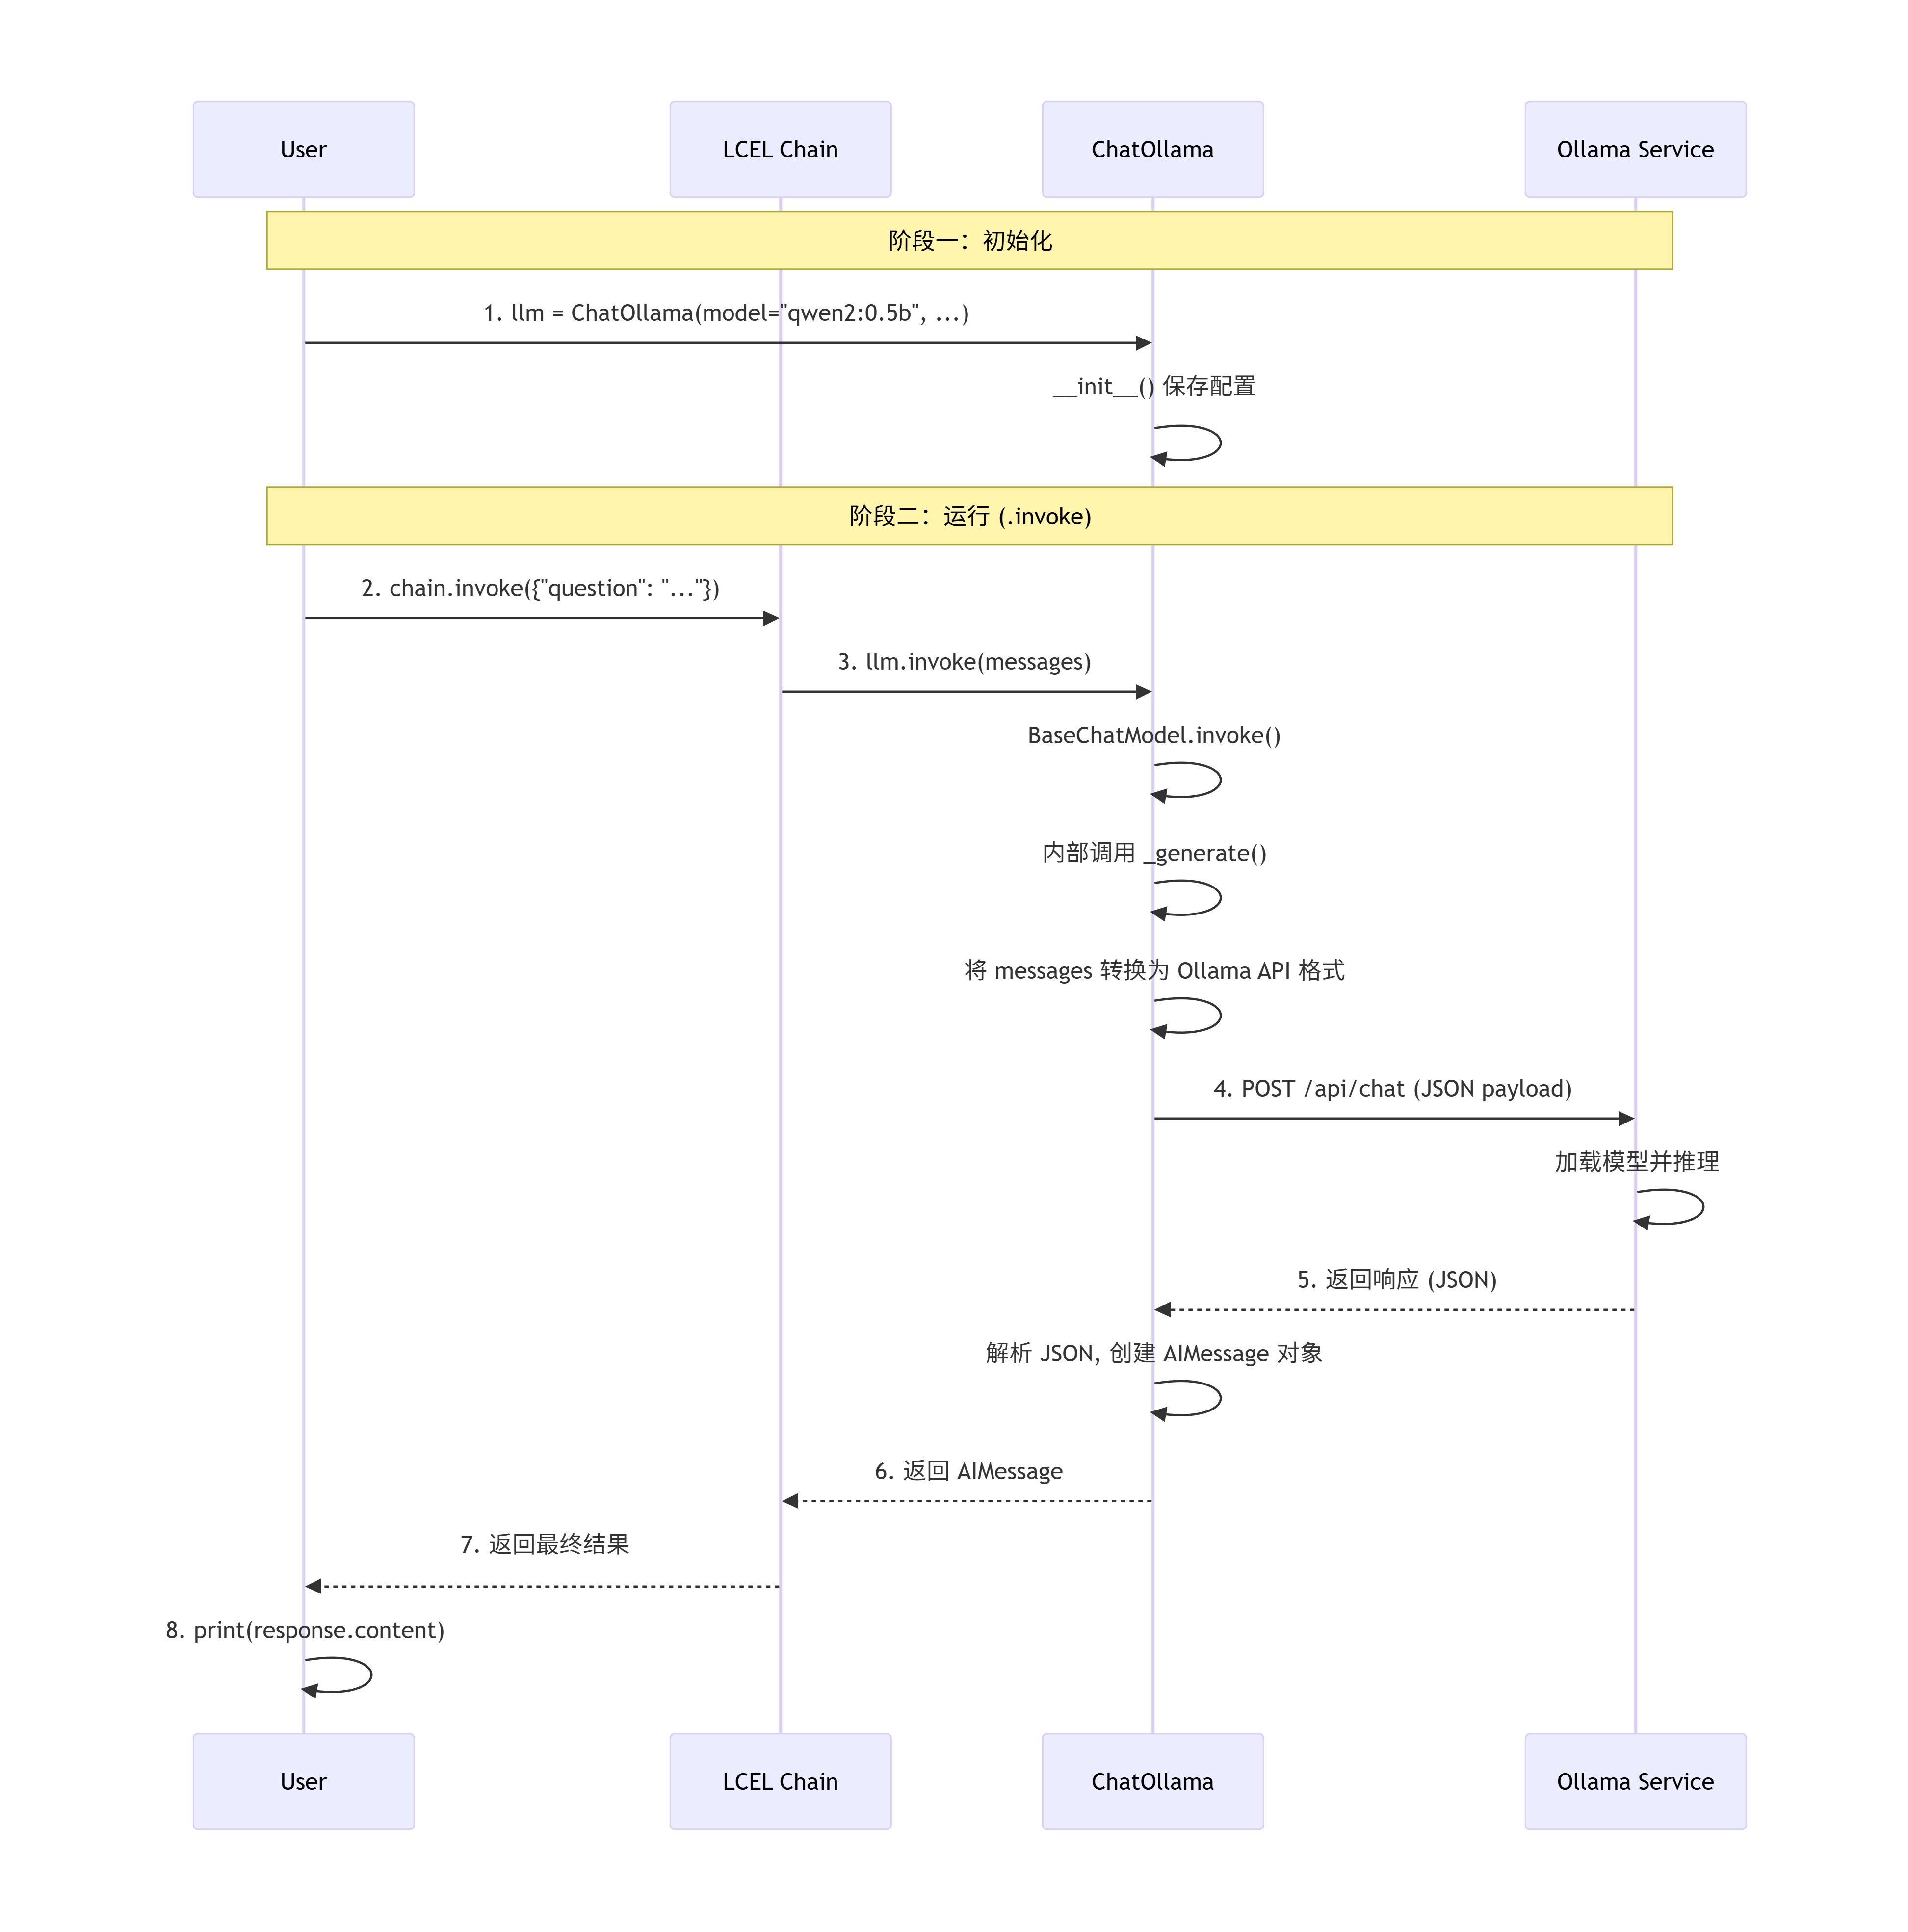



### 补充说明

-   **关于 `langchain_community`**：代码中使用的 `langchain_community.chat_models.ChatOllama` 在较新版本的 LangChain 中已被标记为弃用，官方建议迁移到独立的 `langchain_ollama` 包。不过，它们内部的运行逻辑是完全一致的。

-   **返回值类型**：`invoke` 方法返回的是一个 `AIMessage` 对象，而非直接的字符串。这个对象除了 `content`（回答内容）之外，还可能包含其他元数据，例如 `response_metadata`（里面会有 token 使用量、耗时等信息）。
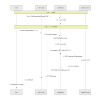